### Import Data & Library

### Install Library

In [10]:
!pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn

### Import Library

In [11]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (make_scorer, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

### Import Data

In [12]:
df = pd.read_csv('HR Employee.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# EDA

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 34 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1470 non-null   int64  
 1   Attrition                 1470 non-null   int64  
 2   BusinessTravel            1470 non-null   object 
 3   DailyRate                 1470 non-null   int64  
 4   Department                1470 non-null   object 
 5   DistanceFromHome          1470 non-null   int64  
 6   Education                 1470 non-null   int64  
 7   EducationField            1470 non-null   object 
 8   EnvironmentSatisfaction   1470 non-null   int64  
 9   Gender                    1470 non-null   object 
 10  HourlyRate                1470 non-null   int64  
 11  JobInvolvement            1470 non-null   int64  
 12  JobLevel                  1470 non-null   int64  
 13  JobRole                   1470 non-null   object 
 14  JobSatis

### Analisis Deskriptif

In [32]:
df.describe()

,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,IncomePerYearExp,PromotionGap,SatisfactionMean
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,0.161224,802.485714,9.192517,2.912925,2.721769,65.891156,2.729932,2.063946,2.728571,...,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129,587.575385,0.236458,2.730952
std,9.135373,0.367863,403.509100,8.106864,1.024165,1.093082,20.329428,0.711561,1.106940,1.102846,...,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136,284.650784,0.269358,0.505815
min,18.000000,0.000000,102.000000,1.000000,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,95.285714,0.000000,1.000000
25%,30.000000,0.000000,465.000000,2.000000,2.000000,2.000000,48.000000,2.000000,1.000000,2.000000,...,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000,374.232143,0.000000,2.500000
50%,36.000000,0.000000,802.000000,7.000000,3.000000,3.000000,66.000000,3.000000,2.000000,3.000000,...,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000,549.220648,0.142857,2.750000
75%,43.000000,0.000000,1157.000000,14.000000,4.000000,4.000000,83.750000,3.000000,3.000000,4.000000,...,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000,738.303846,0.428571,3.000000
max,60.000000,1.000000,1499.000000,29.000000,5.000000,4.000000,100.000000,4.000000,5.000000,4.000000,...,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000,1904.000000,0.916667,4.000000


### Missing Value

In [37]:
print("Total missing :", df.isna().sum().sum())
print("Duplikat baris:", df.duplicated().sum())

Total missing : 0
Duplikat baris: 0


### Distribusi Attrition

In [38]:
# Distribusi target
tgt = df["Attrition"].map({"Yes": 1, "No": 0}) if df["Attrition"].dtype == object else df["Attrition"]
counts = tgt.value_counts().sort_index()
print(counts, "\nProporsi:\n", tgt.value_counts(normalize=True).round(4))

Attrition
0    1233
1     237
Name: count, dtype: int64 
Proporsi:
 Attrition
0    0.8388
1    0.1612
Name: proportion, dtype: float64


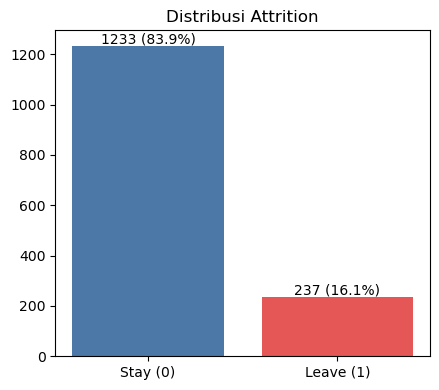

Imbalance ratio (mayoritas:minoritas) = 5.20 : 1


In [39]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.bar(["Stay (0)", "Leave (1)"], counts.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, f"{v} ({v/len(tgt):.1%})", ha="center")
ax.set_title("Distribusi Attrition"); plt.tight_layout(); plt.show()
print(f"Imbalance ratio (mayoritas:minoritas) = {counts[0]/counts[1]:.2f} : 1")

### Feature Engineering

In [40]:
# Buang kolom ID/konstan jika masih ada
drop_cols = [c for c in ["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"] if c in df.columns]
df = df.drop(columns=drop_cols)

# Target 0/1 (hanya dikonversi jika masih teks)
if df["Attrition"].dtype == object:
    df["Attrition"] = (df["Attrition"] == "Yes").astype(int)
assert set(df["Attrition"].unique()) <= {0, 1}
print("Proporsi Attrition:", df["Attrition"].mean().round(4))   # harus ~0.16

# Fitur turunan
df["IncomePerYearExp"] = df["MonthlyIncome"] / (df["TotalWorkingYears"] + 1)
df["PromotionGap"]     = df["YearsSinceLastPromotion"] / (df["YearsAtCompany"] + 1)
df["SatisfactionMean"] = df[["JobSatisfaction", "EnvironmentSatisfaction",
                             "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)

# Pengelompokan tipe fitur (dipakai seluruh anggota)
CONT = ["Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome",
        "MonthlyRate", "NumCompaniesWorked", "PercentSalaryHike", "TotalWorkingYears",
        "TrainingTimesLastYear", "YearsAtCompany", "YearsInCurrentRole",
        "YearsSinceLastPromotion", "YearsWithCurrManager",
        "IncomePerYearExp", "PromotionGap", "SatisfactionMean"]
ORD  = ["Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel",
        "JobSatisfaction", "PerformanceRating", "RelationshipSatisfaction",
        "StockOptionLevel", "WorkLifeBalance"]
CAT  = ["BusinessTravel", "Department", "EducationField", "Gender",
        "JobRole", "MaritalStatus", "OverTime"]

missing = [c for c in CONT + ORD + CAT if c not in df.columns]
extra   = [c for c in df.columns if c not in CONT + ORD + CAT + ["Attrition"]]
assert not missing, f"Kolom hilang: {missing}"
print("Kolom tidak terpakai:", extra)    # idealnya []

Proporsi Attrition: 0.1612
Kolom tidak terpakai: []


### Korelasi Data

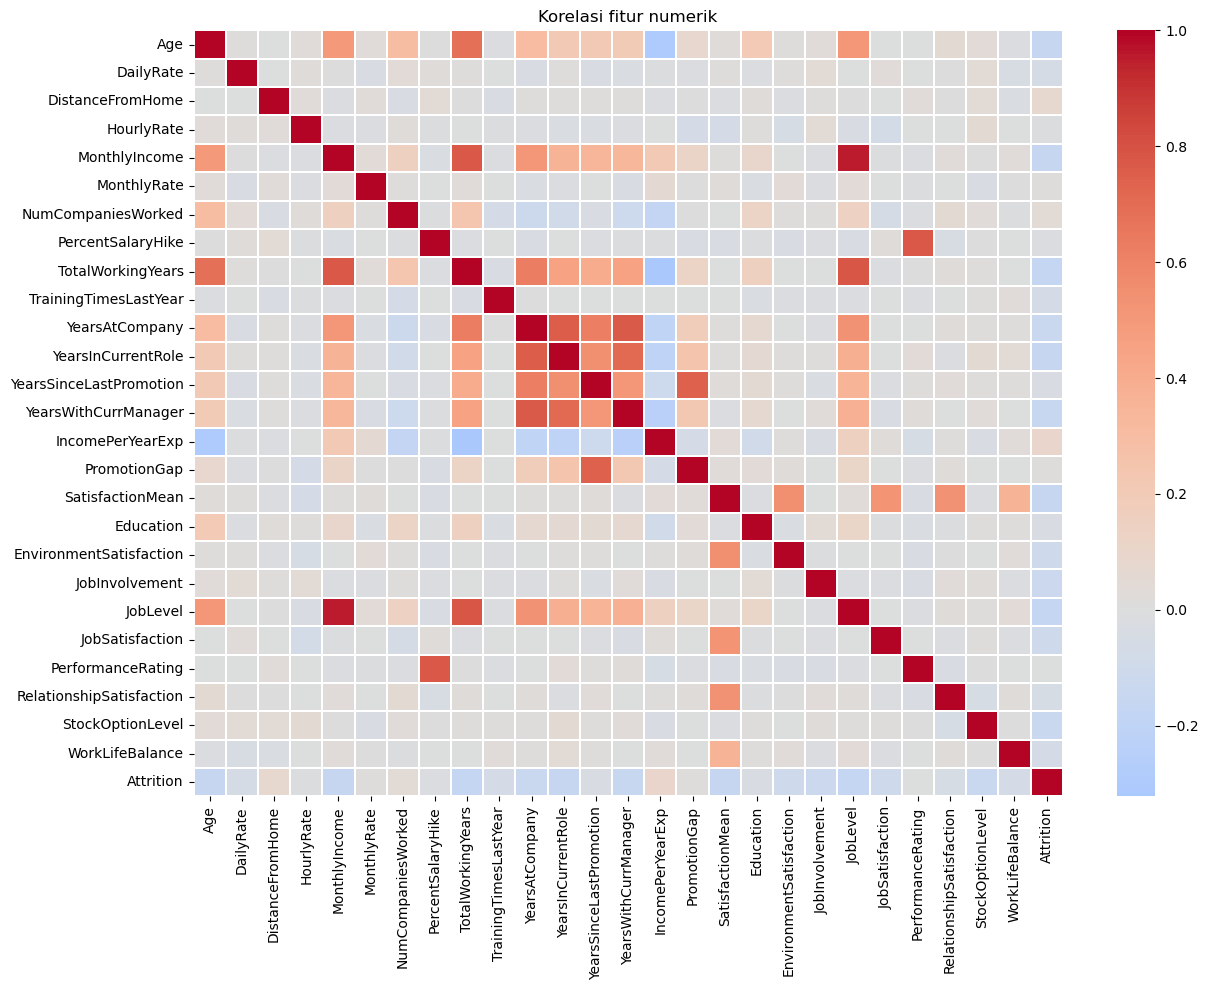

10 fitur paling berkorelasi dengan Attrition:
 TotalWorkingYears      -0.171
JobLevel               -0.169
YearsInCurrentRole     -0.161
MonthlyIncome          -0.160
Age                    -0.159
SatisfactionMean       -0.159
YearsWithCurrManager   -0.156
StockOptionLevel       -0.137
YearsAtCompany         -0.134
JobInvolvement         -0.130
Name: Attrition, dtype: float64

Pasangan korelasi > 0.7:
 MonthlyIncome            JobLevel                0.950
TotalWorkingYears        JobLevel                0.782
PercentSalaryHike        PerformanceRating       0.774
MonthlyIncome            TotalWorkingYears       0.773
YearsAtCompany           YearsWithCurrManager    0.769
                         YearsInCurrentRole      0.759
YearsSinceLastPromotion  PromotionGap            0.745
YearsInCurrentRole       YearsWithCurrManager    0.714
dtype: float64


In [ ]:
num_cols = CONT + ORD
corr = df[num_cols + ["Attrition"]].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, linewidths=.3)
plt.title("Korelasi fitur numerik"); plt.tight_layout(); plt.show()

top = corr["Attrition"].drop("Attrition").sort_values(key=abs, ascending=False).head(10)
print("10 fitur paling berkorelasi dengan Attrition:\n", top.round(3))

# Pasangan fitur sangat berkorelasi (indikasi multikolinearitas)
c = corr.drop("Attrition").drop(columns="Attrition").abs()
pairs = (c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
           .sort_values(ascending=False))
print("\nPasangan korelasi > 0.7:\n", pairs[pairs > 0.7].round(3))

# Pembuatan Model

### Split Data

In [44]:
SEED = 42

X = df.drop(columns="Attrition")
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)
y_train, y_test = y_train.reset_index(drop=True), y_test.reset_index(drop=True)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Attrition train:", y_train.mean().round(4), "| test:", y_test.mean().round(4))

Train: (1176, 33) | Test: (294, 33)
Attrition train: 0.1616 | test: 0.1599


### Pembuatan Fungsi Model Baseline dan Pipeline

In [45]:
def make_preprocessor(extra_num=()):
    """Scaling fitur numerik + one-hot kategorikal. Di-fit hanya pada data train tiap fold."""
    return ColumnTransformer([
        ("num", StandardScaler(), CONT + ORD + list(extra_num)),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

def make_model(name, class_weight=None):
    if name == "LogReg":
        return LogisticRegression(max_iter=2000, class_weight=class_weight, random_state=SEED)
    if name == "RandForest":      # parameter default (baseline)
        return RandomForestClassifier(class_weight=class_weight, random_state=SEED, n_jobs=-1)
    raise ValueError(name)

def build_pipeline(model_name, imb=None):
    """
    imb: None | 'cw' (class weight) | 'smote'
    Resampling berada DI DALAM pipeline: hanya dijalankan saat fit (data train fold),
    tidak pernah menyentuh data validasi.
    """
    steps = [("pre", make_preprocessor())]
    if imb == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    cw = "balanced" if imb == "cw" else None
    steps.append(("clf", make_model(model_name, class_weight=cw)))
    return ImbPipeline(steps)

### Pembuatan Fungsi Cross Validation dan Metrik Evaluasi

In [46]:
SCORING = {
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall":    make_scorer(recall_score),
    "F1":        make_scorer(f1_score),
    "BalAcc":    make_scorer(balanced_accuracy_score),
    "ROC_AUC":   "roc_auc",
    "PR_AUC":    "average_precision",
}

def get_cv(n_splits=5):
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)

def run_cv(pipeline, X, y, n_splits=5):
    """Stratified k-fold. Mengembalikan rata-rata dan simpangan baku tiap metrik."""
    res = cross_validate(pipeline, X, y, cv=get_cv(n_splits), scoring=SCORING,
                         n_jobs=1, error_score="raise")
    out = {}
    for m in SCORING:
        out[m] = res[f"test_{m}"].mean()
        out[f"{m}_std"] = res[f"test_{m}"].std()
    return out

def oof_proba(pipeline, X, y, n_splits=5):
    """Probabilitas out-of-fold (untuk threshold tuning)."""
    return cross_val_predict(pipeline, X, y, cv=get_cv(n_splits), method="predict_proba")[:, 1]

def compute_metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"Precision": precision_score(y_true, pred, zero_division=0),
            "Recall":    recall_score(y_true, pred),
            "F1":        f1_score(y_true, pred),
            "BalAcc":    balanced_accuracy_score(y_true, pred),
            "ROC_AUC":   roc_auc_score(y_true, proba),
            "PR_AUC":    average_precision_score(y_true, proba)}

### Train Model Baseline

In [47]:
IMB_OPTIONS = {"Tanpa penanganan": None, "Class weight": "cw", "SMOTE": "smote"}
rows = []
for model_name in ["LogReg", "RandForest"]:
    for imb_name, imb in IMB_OPTIONS.items():
        r = run_cv(build_pipeline(model_name, imb), X_train, y_train)
        r.update(Model=model_name, Imbalance=imb_name)
        rows.append(r)
        print(f"{model_name:10s} | {imb_name:17s} | F1={r['F1']:.3f}±{r['F1_std']:.3f} "
              f"Recall={r['Recall']:.3f} PR_AUC={r['PR_AUC']:.3f}")

# Tabel ringkas mean ± std
show = cv_baseline[["Model", "Imbalance"]].copy()
for m in ["Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]:
    show[m] = cv_baseline.apply(lambda r: f"{r[m]:.3f} ± {r[m+'_std']:.3f}", axis=1)
display(show)

LogReg     | Tanpa penanganan  | F1=0.570±0.080 Recall=0.453 PR_AUC=0.667
LogReg     | Class weight      | F1=0.488±0.025 Recall=0.732 PR_AUC=0.624
LogReg     | SMOTE             | F1=0.495±0.029 Recall=0.700 PR_AUC=0.608
RandForest | Tanpa penanganan  | F1=0.336±0.108 Recall=0.221 PR_AUC=0.570
RandForest | Class weight      | F1=0.456±0.082 Recall=0.363 PR_AUC=0.551
RandForest | SMOTE             | F1=0.429±0.071 Recall=0.311 PR_AUC=0.571


,Model,Imbalance,Precision,Recall,F1,ROC_AUC,PR_AUC
0,LogReg,Tanpa penanganan,0.779 ± 0.069,0.453 ± 0.082,0.570 ± 0.080,0.841 ± 0.030,0.667 ± 0.059
1,LogReg,Class weight,0.368 ± 0.026,0.732 ± 0.071,0.488 ± 0.025,0.829 ± 0.031,0.624 ± 0.077
2,LogReg,SMOTE,0.384 ± 0.023,0.700 ± 0.079,0.495 ± 0.029,0.826 ± 0.032,0.608 ± 0.068
3,RandForest,Tanpa penanganan,0.842 ± 0.098,0.221 ± 0.091,0.336 ± 0.108,0.817 ± 0.030,0.570 ± 0.047
4,RandForest,Class weight,0.638 ± 0.111,0.363 ± 0.084,0.456 ± 0.082,0.801 ± 0.034,0.551 ± 0.071
5,RandForest,SMOTE,0.748 ± 0.113,0.311 ± 0.071,0.429 ± 0.071,0.814 ± 0.036,0.571 ± 0.048


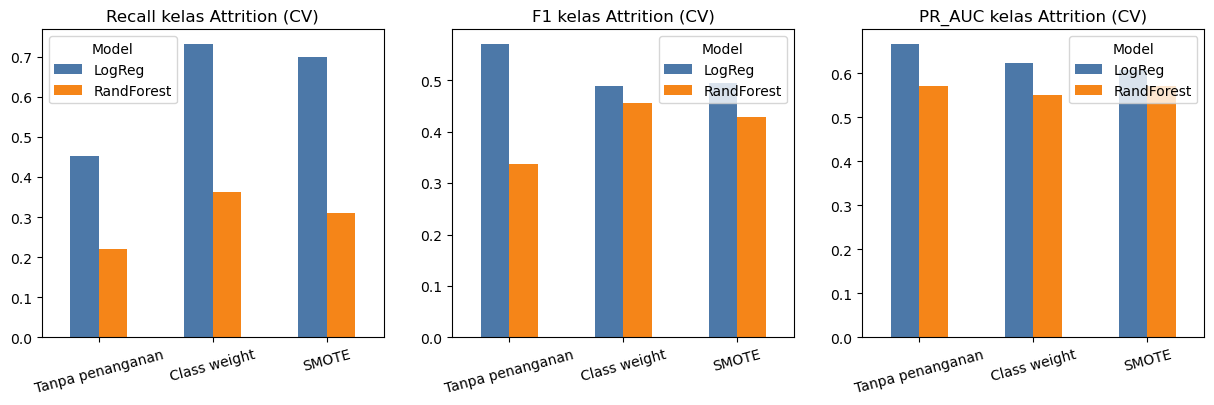

In [48]:
# Visualisasi before/after imbalance handling
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["Recall", "F1", "PR_AUC"]):
    piv = cv_baseline.pivot(index="Imbalance", columns="Model", values=metric).loc[list(IMB_OPTIONS)]
    piv.plot(kind="bar", ax=ax, rot=15, color=["#4C78A8", "#F58518"])
    ax.set_title(f"{metric} kelas Attrition (CV)"); ax.set_xlabel("")

In [50]:
test_rows = []
for model_name in ["LogReg", "RandForest"]:
    for imb_name, imb in IMB_OPTIONS.items():
        pipe = build_pipeline(model_name, imb).fit(X_train, y_train)
        r = compute_metrics(y_test, pipe.predict_proba(X_test)[:, 1])
        r.update(Model=model_name, Imbalance=imb_name)
        test_rows.append(r)

test_baseline = pd.DataFrame(test_rows)[["Model", "Imbalance", "Precision", "Recall", "F1", "BalAcc", "ROC_AUC", "PR_AUC"]]
display(test_baseline.round(3))

,Model,Imbalance,Precision,Recall,F1,BalAcc,ROC_AUC,PR_AUC
0,LogReg,Tanpa penanganan,0.593,0.340,0.432,0.648,0.818,0.581
1,LogReg,Class weight,0.367,0.617,0.460,0.707,0.809,0.558
2,LogReg,SMOTE,0.382,0.617,0.472,0.713,0.808,0.553
3,RandForest,Tanpa penanganan,0.538,0.149,0.233,0.562,0.775,0.435
4,RandForest,Class weight,0.452,0.298,0.359,0.615,0.785,0.439
5,RandForest,SMOTE,0.619,0.277,0.382,0.622,0.790,0.499


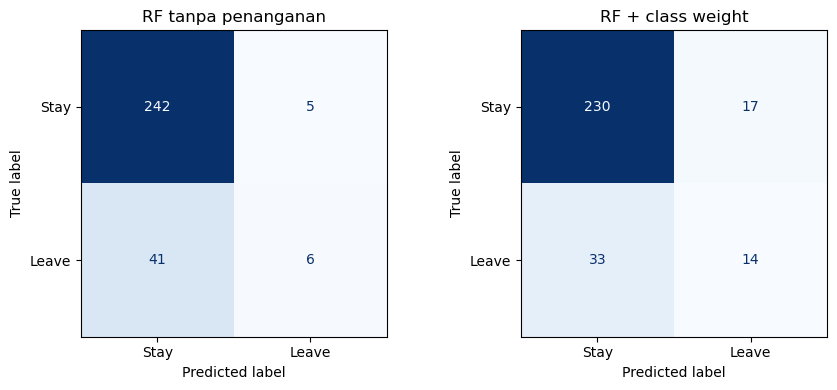

In [51]:
# Confusion matrix baseline (RF default tanpa penanganan vs RF + class weight)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, imb) in zip(axes, [("RF tanpa penanganan", None), ("RF + class weight", "cw")]):
    pipe = build_pipeline("RandForest", imb).fit(X_train, y_train)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pipe.predict(X_test)),
                           display_labels=["Stay", "Leave"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title)
plt.tight_layout(); plt.show()